# NB3 - SLIC superpixels and dual-topology graph construction (GeoGraphNet)

**Run on:** CPU (accelerator: None). **Input to add:** the Kaggle Dataset made from the NB1 output
(it must contain `X16_float16.npy`, `folds.csv`, `labels.npy`).

**What this notebook does**
1. Segments every 64x64 patch with SLIC on the false-colour composite (B8, B4, B3).
2. Sweeps K in {16, 25, 36, 49} and compactness in {10, 20} on a stratified subset and reports segmentation statistics.
3. Builds, for the chosen configurations, a graph per patch: nodes = superpixels, edges = spatial (region adjacency) + spectral (k-NN by Spectral Angle Mapper, non-adjacent), edge attributes = [centroid distance, SAM, shared-boundary ratio].
4. Caches the graphs as `graphs_K{K}_m{m}.npz` and writes `geograph_graph.py` (the builder, reused in NB4 and in NB6 where corrupted images need their graphs rebuilt).

**Node features stored here (36 values, raw units):** mean of 16 channels, std of 16 channels, centroid (x, y) in [0,1], area ratio, perimeter/area.
The deep CNN features (masked mean and max pooling of the CNN feature map) are added in NB4, and standardisation is applied there with training-fold statistics only.

**Edge convention:** `edge_index[0]` = source j, `edge_index[1]` = target i (PyG message direction j -> i). The boundary ratio is L_ij / Perimeter(R_i) of the target region.

## Cell 1 - Load the NB1 data

In [1]:
import os, glob, json, time, sys, subprocess
import numpy as np, pandas as pd
try:
    import skimage
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-image"], check=True)
    import skimage
print("scikit-image", skimage.__version__, "| CPUs:", os.cpu_count())

paths = glob.glob("/kaggle/input/**/X16_float16.npy", recursive=True)
assert paths, "X16_float16.npy not found: add the NB1 output dataset under Input"
assert len(paths) == 1, f"Several X16_float16.npy found (old NB1 dataset still in Input?). Keep only the fixed NB1 dataset: {paths}"
D = os.path.dirname(paths[0])
print("NB1 data folder:", D, "|", sorted(os.listdir(D)))

X16 = np.load(f"{D}/X16_float16.npy", mmap_mode="r")
idx = pd.read_csv(f"{D}/folds.csv")
y = idx["label"].values
assert X16.shape == (len(idx), 16, 64, 64), X16.shape
WORK = "/kaggle/working"
os.makedirs(WORK, exist_ok=True)
# fixed-NB1 check: NDBI must use B11 (mean about -0.18; the old B12-based version is about -0.38)
_ri = np.sort(np.random.default_rng(0).choice(len(X16), 2000, replace=False))
_ndbi = float(np.asarray(X16[_ri, 15], dtype=np.float32).mean())
print("NDBI mean (first 2000 patches): %.4f" % _ndbi)
assert _ndbi > -0.25, "This looks like the OLD X16 (B12-based NDBI). Use the fixed NB1 output."
print("X16:", X16.shape, X16.dtype, "| classes:", sorted(idx["class"].unique()))

scikit-image 0.25.2 | CPUs: 4
NB1 data folder: /kaggle/input/datasets/sudeeptamandal/eurosat-geograph-nb1-v2 | ['X13_uint16.npy', 'X16_float16.npy', 'channel_stats.json', 'data_root.txt', 'eda_band_means.png', 'folds.csv', 'labels.npy', 'near_duplicates.csv']
NDBI mean (first 2000 patches): -0.1872
X16: (27000, 16, 64, 64) float16 | classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


## Cell 2 - Graph builder module

The builder is written to `geograph_graph.py` so that NB4 and NB6 import exactly the same code.
Channel order: 0-12 = B1..B8, B9, B10, B11, B12, B8A (scaled, storage order), 13 = NDVI, 14 = NDWI, 15 = NDBI. The false-colour composite is (B8, B4, B3) = channels (7, 3, 2).

In [2]:
MODULE = r'''
import numpy as np
from skimage.segmentation import slic

N_STATIC = 36          # 16 mean + 16 std + cx, cy, area ratio, perimeter/area
_SHARED = {}           # filled by the notebook before forking workers


def seg_input(x16, scale):
    # false-colour composite (NIR B8, Red B4, Green B3), global per-channel scaling to [0, 1]
    fc = np.stack([x16[7], x16[3], x16[2]], -1).astype(np.float32)
    return np.clip(fc / np.asarray(scale, np.float32), 0, 1)


def segment(x16, K, m, scale):
    lab = slic(seg_input(x16, scale), n_segments=K, compactness=m, start_label=0,
               channel_axis=-1, enforce_connectivity=True)
    _, inv = np.unique(lab.ravel(), return_inverse=True)      # consecutive ids 0..n-1
    return inv.reshape(64, 64).astype(np.int16)


def adjacency(lab, n):
    # symmetric matrix: number of 4-neighbour pixel pairs shared by regions i and j
    a = np.concatenate([lab[:, :-1].ravel(), lab[:-1, :].ravel()]).astype(np.int64)
    b = np.concatenate([lab[:, 1:].ravel(), lab[1:, :].ravel()]).astype(np.int64)
    d = a != b
    M = np.bincount(a[d] * n + b[d], minlength=n * n).reshape(n, n).astype(np.float32)
    return M + M.T


def seg_quality(x16, lab, scale, tiny=20):
    n = int(lab.max()) + 1
    fc = seg_input(x16, scale).reshape(-1, 3)
    l = lab.ravel()
    cnt = np.bincount(l, minlength=n).astype(np.float64)
    sse_w = 0.0
    for c in range(3):
        s1 = np.bincount(l, weights=fc[:, c], minlength=n)
        s2 = np.bincount(l, weights=fc[:, c] ** 2, minlength=n)
        sse_w += float((s2 - s1 ** 2 / cnt).sum())
    sse_t = float(((fc - fc.mean(0)) ** 2).sum())
    ev = 1.0 - sse_w / max(sse_t, 1e-12)                      # explained variation
    M = adjacency(lab, n)
    return dict(n=n, mean_size=4096.0 / n, tiny_frac=float((cnt < tiny).mean()), ev=ev,
                spatial_edges=int((M > 0).sum()))


def build_graph(x16, K, m, scale, k_spec=3):
    x = np.asarray(x16, dtype=np.float32)
    lab = segment(x, K, m, scale)
    n = int(lab.max()) + 1
    assert n <= 255
    l = lab.ravel().astype(np.int64)
    xf = x.reshape(16, -1)
    cnt = np.bincount(l, minlength=n).astype(np.float64)
    mean = np.stack([np.bincount(l, weights=xf[c], minlength=n) for c in range(16)], 1) / cnt[:, None]
    sq = np.stack([np.bincount(l, weights=xf[c] ** 2, minlength=n) for c in range(16)], 1) / cnt[:, None]
    std = np.sqrt(np.maximum(sq - mean ** 2, 0))
    yy, xx = np.mgrid[0:64, 0:64]
    cx = np.bincount(l, weights=xx.ravel().astype(np.float64), minlength=n) / cnt / 63.0
    cy = np.bincount(l, weights=yy.ravel().astype(np.float64), minlength=n) / cnt / 63.0

    M = adjacency(lab, n)
    border = (np.bincount(lab[0, :], minlength=n) + np.bincount(lab[-1, :], minlength=n) +
              np.bincount(lab[:, 0], minlength=n) + np.bincount(lab[:, -1], minlength=n))
    P = M.sum(1) + border                                      # perimeter in pixel-edge units
    node = np.concatenate([mean, std, cx[:, None], cy[:, None], (cnt / 4096.0)[:, None],
                           (P / cnt)[:, None]], 1).astype(np.float32)

    u = mean[:, :13]
    u = u / (np.linalg.norm(u, axis=1, keepdims=True) + 1e-6)
    S = np.arccos(np.clip(u @ u.T, -1.0, 1.0))                 # Spectral Angle Mapper (radians)
    D = np.sqrt((cx[:, None] - cx[None, :]) ** 2 + (cy[:, None] - cy[None, :]) ** 2)

    di, sj = np.nonzero(M > 0)                                 # spatial: target i, source j
    sp_attr = np.stack([D[di, sj], S[di, sj], M[di, sj] / P[di]], 1)

    kk = min(k_spec, n - 1)
    Sm = S.copy(); Sm[M > 0] = np.inf; np.fill_diagonal(Sm, np.inf)
    if kk > 0:
        nn = np.argsort(Sm, axis=1)[:, :kk]
        di2 = np.repeat(np.arange(n), kk); sj2 = nn.ravel()
        keep = np.isfinite(Sm[di2, sj2]); di2, sj2 = di2[keep], sj2[keep]
    else:
        di2 = sj2 = np.zeros(0, np.int64)
    sc_attr = np.stack([D[di2, sj2], S[di2, sj2], np.zeros(len(di2))], 1)

    ei = np.stack([np.concatenate([sj, sj2]), np.concatenate([di, di2])]).astype(np.int16)
    ea = np.concatenate([sp_attr, sc_attr]).astype(np.float32)
    et = np.concatenate([np.zeros(len(di)), np.ones(len(di2))]).astype(np.int8)
    return dict(lab=lab.astype(np.uint8), n=n, node=node, ei=ei, ea=ea, et=et)


def process_range(args):
    s, e, K, m, scale, k_spec = args
    X = _SHARED["X16"]
    return [build_graph(X[i], K, m, scale, k_spec) for i in range(s, e)]


def pack(results):
    n = np.array([r["n"] for r in results], np.int16)
    ne = np.array([r["ei"].shape[1] for r in results], np.int64)
    return dict(seg=np.stack([r["lab"] for r in results]), n_nodes=n,
                node_ptr=np.concatenate([[0], np.cumsum(n)]).astype(np.int64),
                node_static=np.concatenate([r["node"] for r in results]),
                edge_ptr=np.concatenate([[0], np.cumsum(ne)]).astype(np.int64),
                edge_index=np.concatenate([r["ei"] for r in results], 1),
                edge_attr=np.concatenate([r["ea"] for r in results]),
                edge_type=np.concatenate([r["et"] for r in results]))


def get_graph(G, i):
    a, b = int(G["node_ptr"][i]), int(G["node_ptr"][i + 1])
    c, d = int(G["edge_ptr"][i]), int(G["edge_ptr"][i + 1])
    return dict(seg=G["seg"][i], node=G["node_static"][a:b], ei=G["edge_index"][:, c:d].astype(np.int64),
                ea=G["edge_attr"][c:d], et=G["edge_type"][c:d])
'''
open("/kaggle/working/geograph_graph.py", "w").write(MODULE)

import importlib, sys
if "/kaggle/working" not in sys.path:
    sys.path.insert(0, "/kaggle/working")
import geograph_graph as gg
importlib.reload(gg)

# sanity check on one patch
SCALE0 = np.array([0.5, 0.5, 0.5], np.float32)
g = gg.build_graph(np.asarray(X16[0]), 25, 10, SCALE0)
print("regions:", g["n"], "| node features:", g["node"].shape, "| edges:", g["ei"].shape[1],
      "(spatial", int((g["et"] == 0).sum()), ", spectral", int((g["et"] == 1).sum()), ")")
print("edge-attr ranges  dist: %.3f-%.3f | SAM: %.3f-%.3f | boundary ratio: %.3f-%.3f" % (
    g["ea"][:, 0].min(), g["ea"][:, 0].max(), g["ea"][:, 1].min(), g["ea"][:, 1].max(),
    g["ea"][:, 2].min(), g["ea"][:, 2].max()))

regions: 22 | node features: (22, 36) | edges: 166 (spatial 100 , spectral 66 )
edge-attr ranges  dist: 0.117-1.051 | SAM: 0.006-0.229 | boundary ratio: 0.000-0.655


## Cell 3 - Scaling for SLIC and visual check

SLIC runs on the false-colour image (B8, B4, B3). Each channel is divided by its dataset 99th percentile (estimated on 1,000 random patches) and clipped to [0, 1];
the same scale is saved in `slic_config.json` and must be reused whenever a graph is rebuilt (NB4, NB6).

SLIC scale (p99 of B8, B4, B3): [0.489  0.2961 0.2325]


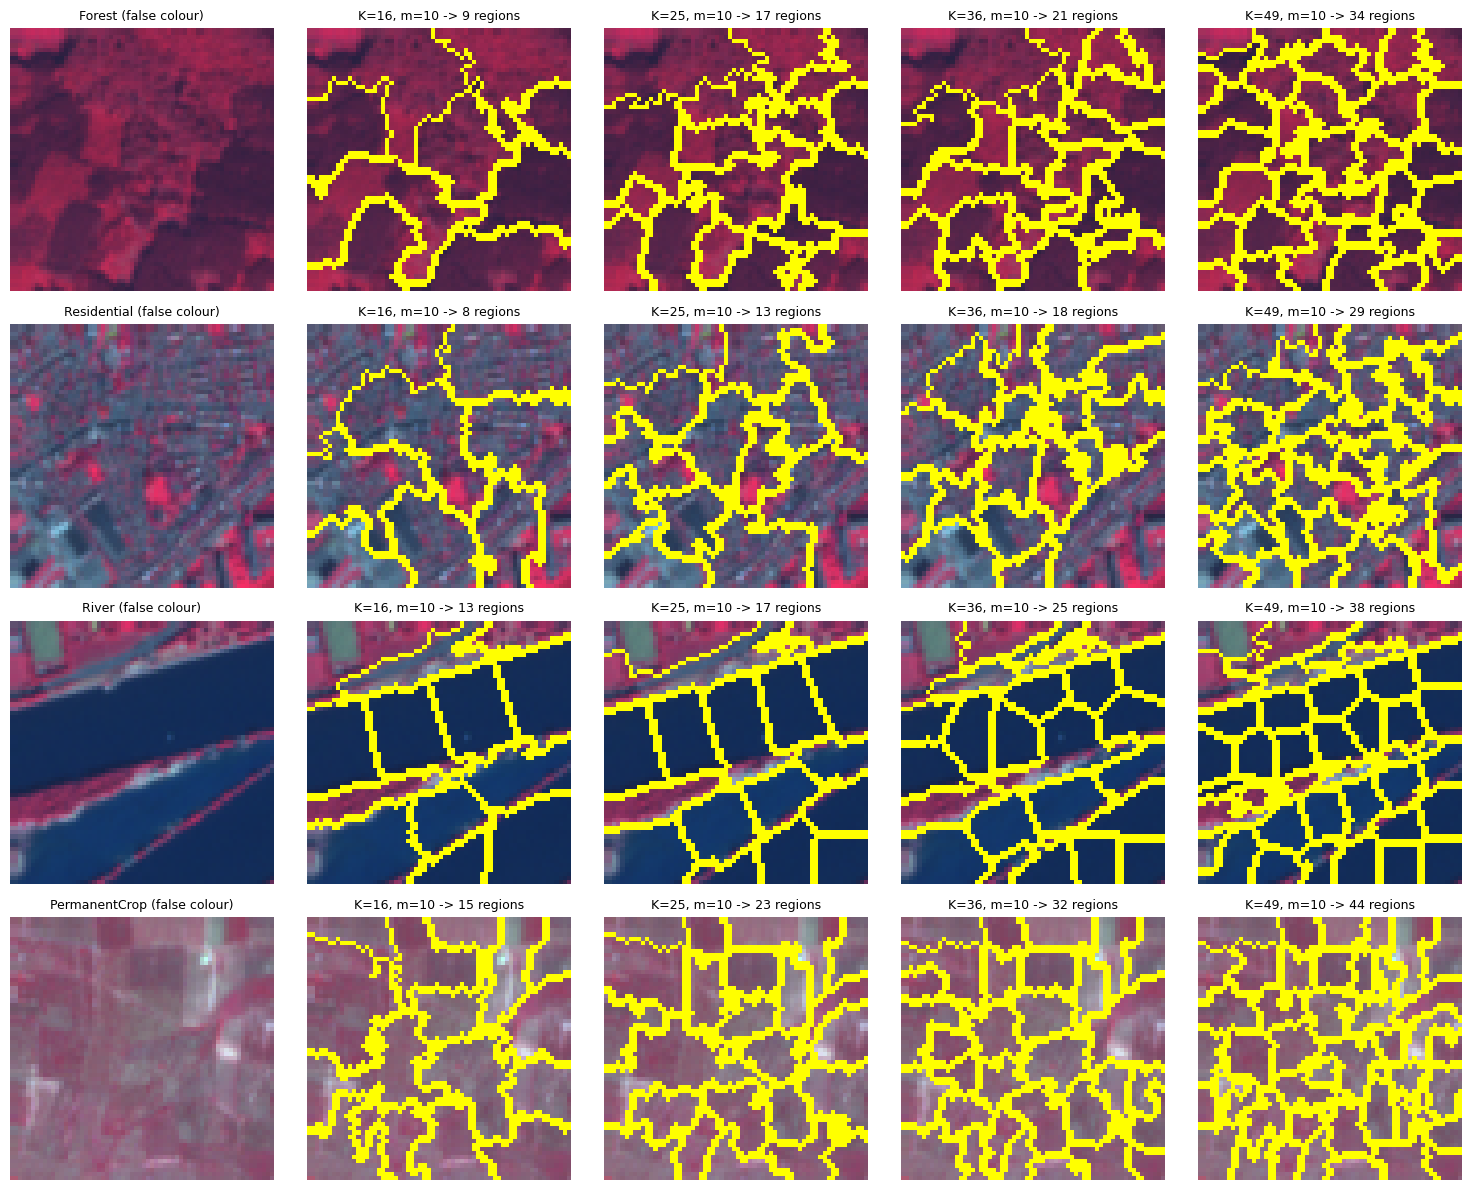

In [3]:
import matplotlib.pyplot as plt
from skimage.segmentation import mark_boundaries

rng = np.random.default_rng(0)
samp = np.sort(rng.choice(len(idx), 1000, replace=False))
fcs = np.asarray(X16[samp][:, [7, 3, 2]], dtype=np.float32)               # B8, B4, B3
SCALE = np.percentile(fcs.transpose(1, 0, 2, 3).reshape(3, -1), 99, axis=1).astype(np.float32)
print("SLIC scale (p99 of B8, B4, B3):", SCALE.round(4))
json.dump({"scale_B8_B4_B3": SCALE.tolist(), "k_spec": 3, "channels_false_colour": [7, 3, 2]},
          open(f"{WORK}/slic_config.json", "w"))

names = sorted(idx["class"].unique())
show = [names.index(c) for c in ["Forest", "Residential", "River", "PermanentCrop"]]
Ks = [16, 25, 36, 49]
fig, ax = plt.subplots(len(show), 1 + len(Ks), figsize=(3 * (1 + len(Ks)), 3 * len(show)))
for r, ci in enumerate(show):
    i = int(rng.choice(np.where(y == ci)[0]))
    x = np.asarray(X16[i])
    fc = gg.seg_input(x, SCALE)
    ax[r, 0].imshow(fc); ax[r, 0].set_title(f"{names[ci]} (false colour)", fontsize=9)
    for c, K in enumerate(Ks):
        lab = gg.segment(x, K, 10, SCALE)
        ax[r, c + 1].imshow(mark_boundaries(fc, lab, color=(1, 1, 0)))
        ax[r, c + 1].set_title(f"K={K}, m=10 -> {lab.max() + 1} regions", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## Cell 4 - K and compactness sweep (stratified subset of 1,500 patches)

Statistics per setting: number of regions, mean region size, share of tiny regions (< 20 px), explained variation of the false-colour image
(1 - within-region variance / total variance), spatial edges per graph, time per patch.
Higher K raises explained variation but makes regions smaller and noisier on 64x64 patches; the final choice is made on validation accuracy in NB4, not here.

sweep subset: (1500, 16, 64, 64)


K=16 m=10:   0%|          | 0/1500 [00:00<?, ?it/s]

K=16 m=20:   0%|          | 0/1500 [00:00<?, ?it/s]

K=25 m=10:   0%|          | 0/1500 [00:00<?, ?it/s]

K=25 m=20:   0%|          | 0/1500 [00:00<?, ?it/s]

K=36 m=10:   0%|          | 0/1500 [00:00<?, ?it/s]

K=36 m=20:   0%|          | 0/1500 [00:00<?, ?it/s]

K=49 m=10:   0%|          | 0/1500 [00:00<?, ?it/s]

K=49 m=20:   0%|          | 0/1500 [00:00<?, ?it/s]

,K,m,regions,regions_min,regions_max,mean_size_px,tiny_regions_pct,explained_var,spatial_edges,ms_per_patch
0,16,10,10.308,1,17,496.141,0.0,0.423,38.063,4.404
1,16,20,13.892,6,17,301.828,0.0,0.514,54.599,4.170
2,25,10,17.030,1,25,287.289,0.0,0.495,70.193,4.820
3,25,20,22.239,14,26,186.832,0.0,0.583,95.287,4.546
4,36,10,25.570,1,36,182.169,0.0,0.549,112.448,5.218
5,36,20,32.503,19,37,127.307,0.0,0.629,146.737,4.999
6,49,10,37.101,6,49,118.113,0.0,0.604,170.696,5.234
7,49,20,45.395,32,49,90.734,0.0,0.674,211.775,5.043


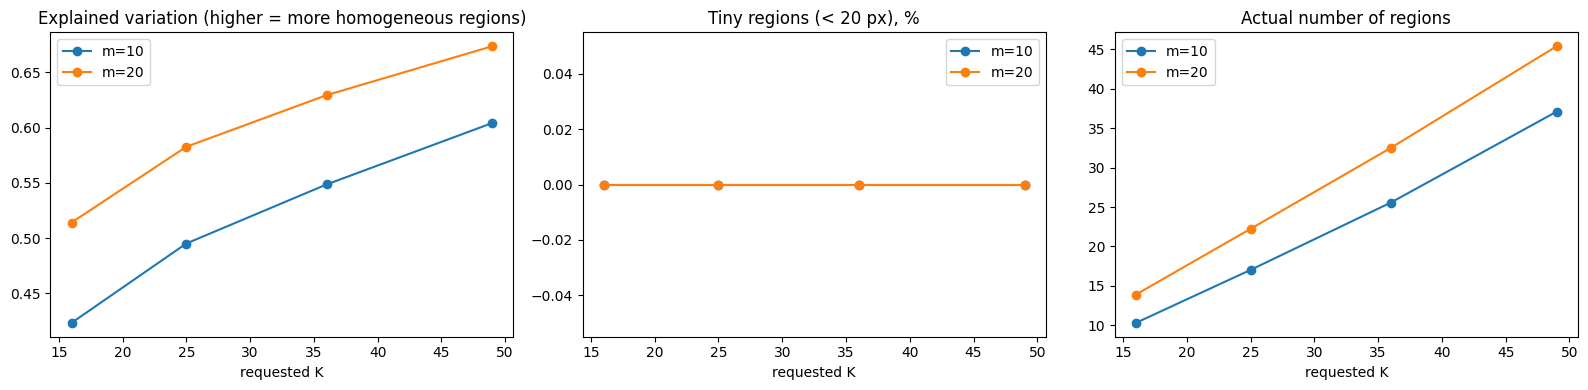

In [4]:
import time
from tqdm.auto import tqdm

per_class = 150
sub = np.sort(np.concatenate([rng.choice(np.where(y == c)[0], per_class, replace=False) for c in range(len(names))]))
Xs = np.asarray(X16[sub])
print("sweep subset:", Xs.shape)

rows = []
for K in [16, 25, 36, 49]:
    for m in [10, 20]:
        q, t0 = [], time.time()
        for x in tqdm(Xs, desc=f"K={K} m={m}", leave=False):
            lab = gg.segment(x, K, m, SCALE)
            q.append(gg.seg_quality(x, lab, SCALE))
        d = pd.DataFrame(q)
        rows.append(dict(K=K, m=m, regions=d["n"].mean(), regions_min=d["n"].min(), regions_max=d["n"].max(),
                         mean_size_px=d["mean_size"].mean(), tiny_regions_pct=100 * d["tiny_frac"].mean(),
                         explained_var=d["ev"].mean(), spatial_edges=d["spatial_edges"].mean(),
                         ms_per_patch=1000 * (time.time() - t0) / len(Xs)))
sweep = pd.DataFrame(rows)
display(sweep.round(3))
sweep.to_csv(f"{WORK}/slic_sweep.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for m, g_ in sweep.groupby("m"):
    ax[0].plot(g_["K"], g_["explained_var"], marker="o", label=f"m={m}")
    ax[1].plot(g_["K"], g_["tiny_regions_pct"], marker="o", label=f"m={m}")
    ax[2].plot(g_["K"], g_["regions"], marker="o", label=f"m={m}")
ax[0].set_title("Explained variation (higher = more homogeneous regions)")
ax[1].set_title("Tiny regions (< 20 px), %"); ax[2].set_title("Actual number of regions")
for a in ax: a.set_xlabel("requested K"); a.legend()
plt.tight_layout(); plt.savefig(f"{WORK}/slic_sweep.png", dpi=130); plt.show()

## Cell 5 - Build and cache the graphs for the chosen configurations

Edit `CONFIGS` after looking at the sweep (default: K = 25 and 36 with compactness 10, as in the project plan).
Workers are started with `fork`, so they share `X16` without copying it. A speed test on 100 patches prints the estimated total time before the full run starts.

In [5]:
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

CONFIGS = [(25, 20), (36, 20)]       # (K, compactness)
K_SPEC = 3
N = len(idx)
CHUNK = 250
NW = max(1, (os.cpu_count() or 1))

gg._SHARED["X16"] = X16
t0 = time.time()
_ = [gg.build_graph(X16[i], 25, 10, SCALE, K_SPEC) for i in range(100)]
per = (time.time() - t0) / 100
print(f"single-process speed: {1000*per:.1f} ms/graph -> about {per*N/NW/60:.1f} min per configuration with {NW} workers")

ctx = mp.get_context("fork")
for K, m in CONFIGS:
    out = f"{WORK}/graphs_K{K}_m{m}.npz"
    if os.path.exists(out):
        print("exists, skipping:", out); continue
    t0 = time.time()
    jobs = [(s, min(s + CHUNK, N), K, m, SCALE, K_SPEC) for s in range(0, N, CHUNK)]
    results = []
    with ProcessPoolExecutor(max_workers=NW, mp_context=ctx) as ex:
        for part in tqdm(ex.map(gg.process_range, jobs), total=len(jobs), desc=f"K={K} m={m}"):
            results.extend(part)
    G = gg.pack(results)
    np.savez(out, **G)
    print(f"K={K}, m={m}: {len(results)} graphs in {(time.time()-t0)/60:.1f} min | nodes {G['node_static'].shape[0]:,} | "
          f"edges {G['edge_index'].shape[1]:,} | file {os.path.getsize(out)/1e6:.0f} MB")

single-process speed: 11.9 ms/graph -> about 1.3 min per configuration with 4 workers


K=25 m=20:   0%|          | 0/108 [00:00<?, ?it/s]

K=25, m=20: 27000 graphs in 19.3 min | nodes 599,733 | edges 4,361,363 | file 272 MB


K=36 m=20:   0%|          | 0/108 [00:00<?, ?it/s]

K=36, m=20: 27000 graphs in 1.2 min | nodes 876,753 | edges 6,575,939 | file 349 MB


## Cell 6 - Integrity checks and graph statistics

In [6]:
def check(G, name, sample=3000):
    n = G["n_nodes"].astype(int); nn = len(n)
    ne = np.diff(G["edge_ptr"])
    assert nn == N and G["node_ptr"][-1] == G["node_static"].shape[0] and G["edge_ptr"][-1] == G["edge_index"].shape[1]
    assert np.isfinite(G["node_static"]).all() and np.isfinite(G["edge_attr"]).all(), "NaN/Inf found"
    assert (G["seg"].reshape(nn, -1).max(1) + 1 == n).all(), "label ids not consecutive"
    ar = G["node_static"][:, 34]
    assert np.allclose(np.add.reduceat(ar, G["node_ptr"][:-1]), 1.0, atol=1e-4), "areas do not sum to 1"
    sp = G["edge_type"] == 0
    br = G["edge_attr"][sp, 2]
    assert br.min() > 0 and br.max() <= 1.0 + 1e-6, "boundary ratio out of (0,1]"
    assert (G["edge_attr"][~sp, 2] == 0).all()
    bad = 0
    for i in np.random.default_rng(0).choice(nn, min(sample, nn), replace=False):
        g = gg.get_graph(G, int(i))
        n_ = g["node"].shape[0]
        assert len(g["et"]) == 0 or (g["ei"].min() >= 0 and g["ei"].max() < n_)
        S = set(map(tuple, g["ei"][:, g["et"] == 0].T.tolist()))
        T = set(map(tuple, g["ei"][:, g["et"] == 1].T.tolist()))
        bad += (not all((b, a) in S for a, b in S)) + (len(S & T) > 0)
        indeg = np.bincount(g["ei"][1, g["et"] == 1], minlength=n_) if (g["et"] == 1).any() else np.zeros(1)
        assert indeg.max() <= K_SPEC
    assert bad == 0, f"{bad} graphs with asymmetric spatial edges or spectral edges overlapping spatial ones"
    print(f"{name}: OK | nodes/graph {n.mean():.1f} (min {n.min()}, max {n.max()}) | edges/graph {ne.mean():.1f} | "
          f"spatial {int(sp.sum())/nn:.1f} | spectral {int((~sp).sum())/nn:.1f} | single-node graphs: {(n == 1).sum()}")

GRAPHS = {}
for K, m in CONFIGS:
    G = dict(np.load(f"{WORK}/graphs_K{K}_m{m}.npz"))
    check(G, f"K={K}, m={m}")
    GRAPHS[(K, m)] = G

K=25, m=20: OK | nodes/graph 22.2 (min 7, max 27) | edges/graph 161.5 | spatial 94.9 | spectral 66.6 | single-node graphs: 0
K=36, m=20: OK | nodes/graph 32.5 (min 13, max 39) | edges/graph 243.6 | spatial 146.1 | spectral 97.4 | single-node graphs: 0


## Cell 7 - Look at the graphs

White lines: spatial (adjacency) edges. Yellow dashed lines: spectral k-NN edges. Dots: superpixel centroids.
Check that spectral edges connect distant regions that look alike, and that adjacent regions are linked by white edges.

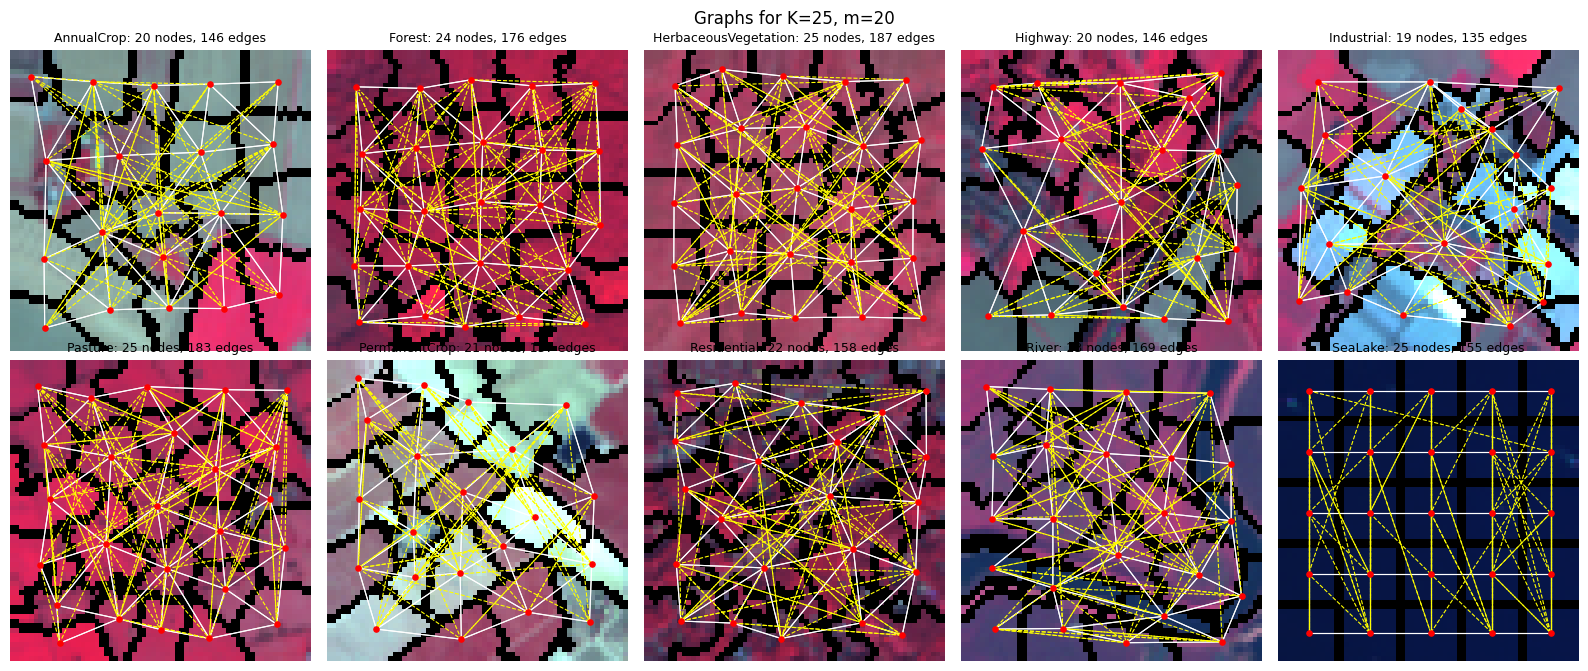

In [7]:
K0, m0 = CONFIGS[0]
G = GRAPHS[(K0, m0)]
fig, ax = plt.subplots(2, 5, figsize=(16, 6.8))
for a, ci in zip(ax.ravel(), range(len(names))):
    i = int(rng.choice(np.where(y == ci)[0]))
    g = gg.get_graph(G, i)
    fc = gg.seg_input(np.asarray(X16[i]), SCALE)
    a.imshow(mark_boundaries(fc, g["seg"].astype(int), color=(0, 0, 0)))
    px, py = g["node"][:, 32] * 63, g["node"][:, 33] * 63
    for (s_, d_), t in zip(g["ei"].T, g["et"]):
        if t == 0: a.plot([px[s_], px[d_]], [py[s_], py[d_]], color="white", lw=0.8)
        else:      a.plot([px[s_], px[d_]], [py[s_], py[d_]], color="yellow", lw=0.8, ls="--")
    a.scatter(px, py, s=14, c="red", zorder=3)
    a.set_title(f"{names[ci]}: {len(g['node'])} nodes, {len(g['et'])} edges", fontsize=9); a.axis("off")
plt.suptitle(f"Graphs for K={K0}, m={m0}"); plt.tight_layout(); plt.savefig(f"{WORK}/graph_examples.png", dpi=130); plt.show()

## Cell 8 - Reload test, PyTorch Geometric conversion and output summary

`get_graph` returns numpy arrays. `to_pyg` shows how NB4 turns a cached graph into a `torch_geometric.data.Data` object
(the CNN-pooled features are added later from the stored segmentation map `seg`).

In [8]:
def to_pyg(G, i, y_arr):
    import torch
    from torch_geometric.data import Data
    g = gg.get_graph(G, i)
    return Data(x=torch.from_numpy(g["node"]), edge_index=torch.from_numpy(g["ei"]),
                edge_attr=torch.from_numpy(g["ea"]), edge_type=torch.from_numpy(g["et"].astype(np.int64)),
                seg=torch.from_numpy(g["seg"].astype(np.int64)), y=torch.tensor(int(y_arr[i])))

try:
    d = to_pyg(GRAPHS[CONFIGS[0]], 0, y)
    print("PyG Data example:", d)
except Exception as e:
    print("PyG not available in this notebook (fine for NB3):", type(e).__name__, "- NB4 installs it")

print("\nfiles in /kaggle/working:")
for f in sorted(os.listdir(WORK)):
    p = os.path.join(WORK, f)
    if os.path.isfile(p):
        print(f"  {f:28s} {os.path.getsize(p)/1e6:9.1f} MB")


PyG not available in this notebook (fine for NB3): ModuleNotFoundError - NB4 installs it

files in /kaggle/working:
  __notebook__.ipynb                 1.6 MB
  geograph_graph.py                  0.0 MB
  graph_examples.png                 1.3 MB
  graphs_K25_m20.npz               271.6 MB
  graphs_K36_m20.npz               349.1 MB
  slic_config.json                   0.0 MB
  slic_sweep.csv                     0.0 MB
  slic_sweep.png                     0.1 MB
